## Cell 1 — Install required packages

In [1]:
!pip install -q requests "scikit-learn>=1.2" pandas numpy matplotlib

## Cell 2 — Import libraries

In [2]:
import requests
import time
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)

warnings.filterwarnings("ignore")
np.random.seed(42)
RANDOM_STATE = 42

## Cell 3 — Load dataset

We query the **openFDA Drug Adverse Event API** (`api.fda.gov/drug/event.json`) for a set of common,
widely-prescribed drugs across different drug classes. This keeps the dataset diverse (not just one drug)
so the model learns general patterns rather than memorizing a single drug's reports.

Source: U.S. FDA FAERS via openFDA — https://open.fda.gov/apis/drug/event/

In [3]:
DRUG_LIST = [
    "aspirin", "ibuprofen", "acetaminophen", "metformin", "atorvastatin",
    "lisinopril", "amoxicillin", "omeprazole", "sertraline", "fluoxetine",
    "warfarin", "insulin", "losartan", "simvastatin", "metoprolol",
    "gabapentin", "tramadol", "prednisone", "levothyroxine", "amlodipine",
    "citalopram", "escitalopram", "hydrochlorothiazide", "clopidogrel", "furosemide",
    "albuterol", "montelukast", "pantoprazole", "duloxetine", "venlafaxine",
    "risperidone", "quetiapine", "methotrexate", "oxycodone", "morphine",
    "diclofenac", "naproxen", "azithromycin", "ciprofloxacin", "doxycycline",
]

def fetch_reports_for_drug(drug_name, limit=200):
    """Query openFDA for adverse event reports naming this drug."""
    url = "https://api.fda.gov/drug/event.json"
    params = {
        "search": f'patient.drug.medicinalproduct:"{drug_name}"',
        "limit": limit,
    }
    try:
        resp = requests.get(url, params=params, timeout=30)
        resp.raise_for_status()
        return resp.json().get("results", [])
    except Exception as e:
        print(f"Skipped {drug_name}: {e}")
        return []

all_records = []
for drug in DRUG_LIST:
    reports = fetch_reports_for_drug(drug, limit=200)
    for r in reports:
        r["_queried_drug"] = drug
    all_records.extend(reports)
    time.sleep(0.3)  # be polite to the public API

print(f"Total raw reports collected: {len(all_records)}")

Total raw reports collected: 8000


## Cell 4 — Inspect the dataset

Look at the raw JSON structure before flattening it into a table.

In [4]:
print("Example top-level fields:", list(all_records[0].keys()))
print()
print("Example patient sub-fields:", list(all_records[0]["patient"].keys()))
print()
print("Example reaction entries:", all_records[0]["patient"]["reaction"][:2])

Example top-level fields: ['safetyreportversion', 'safetyreportid', 'primarysourcecountry', 'occurcountry', 'transmissiondateformat', 'transmissiondate', 'reporttype', 'serious', 'receivedateformat', 'receivedate', 'receiptdateformat', 'receiptdate', 'fulfillexpeditecriteria', 'companynumb', 'duplicate', 'reportduplicate', 'primarysource', 'sender', 'receiver', 'patient', '_queried_drug']

Example patient sub-fields: ['patientsex', 'reaction', 'drug']

Example reaction entries: [{'reactionmeddraversionpt': '17.0', 'reactionmeddrapt': 'Drug hypersensitivity', 'reactionoutcome': '6'}]


## Cell 5 — Data cleaning



In [5]:
def parse_report(r):
    patient = r.get("patient", {})
    reactions = patient.get("reaction", [])
    drugs = patient.get("drug", [])

    # find the primary suspect drug's administration route
    suspect_route = None
    for d in drugs:
        if d.get("drugcharacterization") == "1":
            suspect_route = d.get("drugadministrationroute")
            break

    return {
        "safetyreportid": r.get("safetyreportid"),
        "queried_drug": r.get("_queried_drug"),
        "age": patient.get("patientonsetage"),
        "age_unit": patient.get("patientonsetageunit"),
        "sex": patient.get("patientsex"),
        "weight": patient.get("patientweight"),
        "num_reactions": len(reactions),
        "num_drugs": len(drugs),
        "route": suspect_route,
        "qualification": r.get("primarysource", {}).get("qualification"),
        "country": r.get("occurcountry"),
        "reaction_terms": [x.get("reactionmeddrapt") for x in reactions],
        "serious": r.get("serious"),
    }

df_raw = pd.DataFrame([parse_report(r) for r in all_records])
print("Raw shape:", df_raw.shape)

# remove duplicate reports (FAERS is known to contain duplicate submissions)
df = df_raw.drop_duplicates(subset="safetyreportid").copy()

# age: only trust values reported in years (openFDA unit code 801 = years), clip to a plausible range
df["age"] = pd.to_numeric(df["age"], errors="coerce")
df.loc[df["age_unit"] != "801", "age"] = np.nan
df.loc[(df["age"] < 0) | (df["age"] > 110), "age"] = np.nan

df["weight"] = pd.to_numeric(df["weight"], errors="coerce")

# constant-value fills are safe pre-split: they don't depend on the dataset's distribution
df["sex"] = df["sex"].fillna("0")
df["route"] = df["route"].fillna("Unknown")
df["qualification"] = df["qualification"].fillna("Unknown")
df["country"] = df["country"].fillna("Unknown")

# target: openFDA encodes serious as "1" (yes) / "2" (no)
df["serious"] = df["serious"].map({"1": 1, "2": 0})
df = df.dropna(subset=["serious"]).copy()
df["serious"] = df["serious"].astype(int)

print("Cleaned shape:", df.shape)
print(df["serious"].value_counts(normalize=True).rename("proportion"))

Raw shape: (8000, 13)
Cleaned shape: (5681, 13)
serious
1    0.77592
0    0.22408
Name: proportion, dtype: float64


## Cell 6 — Exploratory analysis

Class balance, age distribution, and top administration routes, plus one view against the target
(seriousness rate by reporter qualification) so the EDA isn't purely univariate.

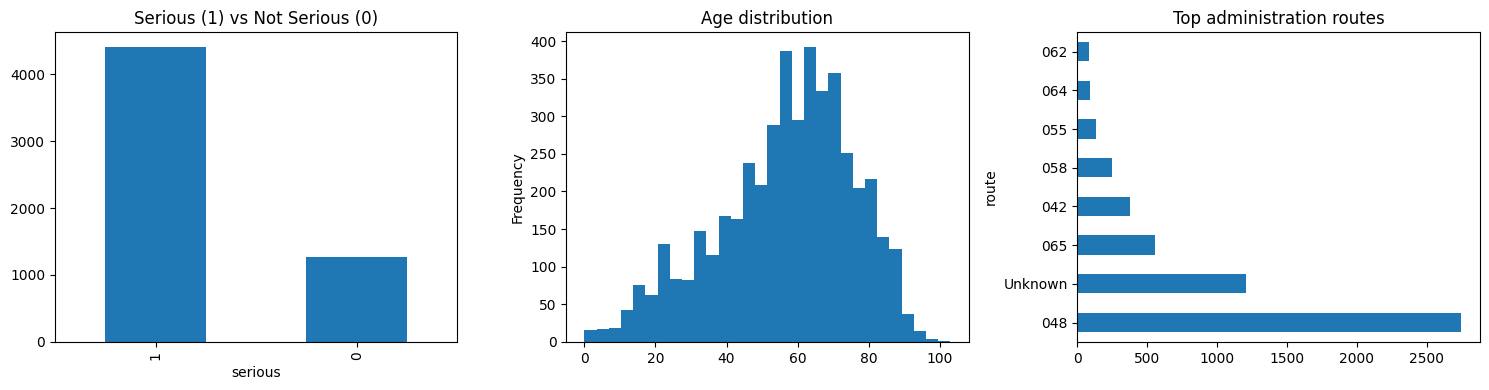

Class balance:
serious
1    0.77592
0    0.22408
Name: proportion, dtype: float64


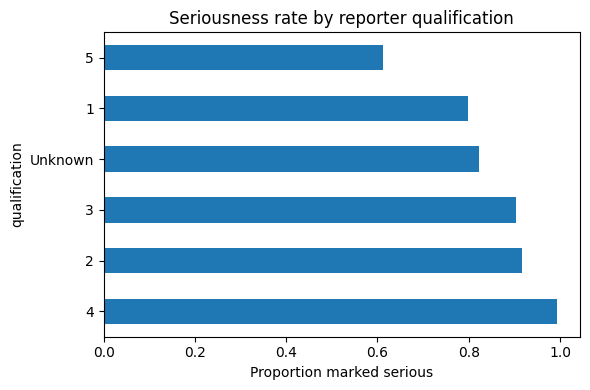

qualification
4          0.994
2          0.916
3          0.903
Unknown    0.822
1          0.799
5          0.613
Name: serious, dtype: float64


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

df["serious"].value_counts().plot(kind="bar", ax=axes[0], title="Serious (1) vs Not Serious (0)")
df["age"].plot(kind="hist", bins=30, ax=axes[1], title="Age distribution")
df["route"].value_counts().head(8).plot(kind="barh", ax=axes[2], title="Top administration routes")

plt.tight_layout()
plt.show()

print("Class balance:")
print(df["serious"].value_counts(normalize=True))

# bivariate view: does seriousness rate vary by who filed the report?
qual_rate = df.groupby("qualification")["serious"].mean().sort_values(ascending=False)
qual_rate.plot(kind="barh", figsize=(6, 4), title="Seriousness rate by reporter qualification")
plt.xlabel("Proportion marked serious")
plt.tight_layout()
plt.show()
print(qual_rate.round(3))

## Cell 7 — Feature / target preparation

The target is `serious`. We keep the raw numeric and categorical columns here — no imputation, no
bucketing, no dummy encoding yet. All of that happens **after** the train/test split (Cell 9), so nothing
computed from the full dataset can leak into the model.

In [6]:
num_cols = ["age", "weight", "num_reactions", "num_drugs"]
cat_cols = ["sex", "route", "qualification", "country"]

X_raw = df[num_cols + cat_cols].copy()
y = df["serious"]

print("Raw feature matrix shape:", X_raw.shape)
X_raw.head()

Raw feature matrix shape: (5681, 8)


,age,weight,num_reactions,num_drugs,sex,route,qualification,country
0,NaN,NaN,1,9,2,Unknown,1,US
1,66.0,NaN,1,11,2,048,5,US
2,NaN,NaN,3,8,2,048,5,US
3,84.0,NaN,2,14,2,Unknown,5,US
4,58.0,82.1,11,20,1,048,Unknown,US


## Cell 8 — Train/test split

Stratified split so both sets keep the same serious/not-serious ratio. Split happens on the *raw*, unprocessed features.

In [7]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("Train size:", X_train_raw.shape, " Test size:", X_test_raw.shape)

Train size: (4544, 8)  Test size: (1137, 8)


## Cell 9 — Preprocessing pipeline 



In [9]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_transformer = OneHotEncoder(
    handle_unknown="infrequent_if_exist", max_categories=11, sparse_output=False
)

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, num_cols),
    ("cat", categorical_transformer, cat_cols),
])

X_train_processed = preprocessor.fit_transform(X_train_raw, y_train)
X_test_processed = preprocessor.transform(X_test_raw)

feature_names = preprocessor.get_feature_names_out()
X_train = pd.DataFrame(X_train_processed, columns=feature_names, index=X_train_raw.index)
X_test = pd.DataFrame(X_test_processed, columns=feature_names, index=X_test_raw.index)

print("Processed train shape:", X_train.shape)
print("Processed test shape:", X_test.shape)
X_train.head()

Processed train shape: (4544, 35)
Processed test shape: (1137, 35)


,num__age,num__weight,num__num_reactions,num__num_drugs,cat__sex_0,cat__sex_1,cat__sex_2,cat__route_030,cat__route_042,cat__route_048,...,cat__country_CA,cat__country_DE,cat__country_ES,cat__country_FR,cat__country_GB,cat__country_IT,cat__country_JP,cat__country_US,cat__country_Unknown,cat__country_infrequent_sklearn
701,0.805197,-0.034530,0.306087,0.620801,0.0,1.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
886,1.617571,-0.034530,0.641154,0.116142,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1014,1.443491,1.492237,0.138554,-0.262353,0.0,1.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
6535,-0.413364,-0.034530,-0.196512,-0.262353,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3945,-0.239283,1.619467,0.306087,-0.136188,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


## Cell 10 — Cross-validation

The original notebook reported metrics from a single 80/20 split, which is a thin evidence base for
three model comparisons. Here we run 5-fold stratified cross-validation **on the training set only**,
re-fitting the preprocessor inside every fold so no fold's validation data ever touches another fold's
imputation/encoding statistics.

Gradient Boosting has no `class_weight` parameter in scikit-learn, unlike the other two models, so its
imbalance handling would otherwise be inconsistent with theirs. We fix that by computing balanced
`sample_weight`s per fold and passing them at `.fit()` time — the documented equivalent for estimators
without `class_weight`.

In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def make_models():
    return {
        "Logistic Regression": LogisticRegression(
            max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE
        ),
        "Random Forest": RandomForestClassifier(
            n_estimators=300, max_depth=10, class_weight="balanced", random_state=RANDOM_STATE
        ),
        "Gradient Boosting": GradientBoostingClassifier(
            n_estimators=200, max_depth=3, random_state=RANDOM_STATE
        ),
    }

metric_names = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
cv_scores = {name: {m: [] for m in metric_names} for name in make_models()}

for fold, (tr_idx, val_idx) in enumerate(cv.split(X_train_raw, y_train), start=1):
    X_tr_fold_raw = X_train_raw.iloc[tr_idx]
    X_val_fold_raw = X_train_raw.iloc[val_idx]
    y_tr_fold = y_train.iloc[tr_idx]
    y_val_fold = y_train.iloc[val_idx]

    fold_preprocessor = clone(preprocessor)
    X_tr_fold = fold_preprocessor.fit_transform(X_tr_fold_raw, y_tr_fold)
    X_val_fold = fold_preprocessor.transform(X_val_fold_raw)

    sw_fold = compute_sample_weight("balanced", y_tr_fold)

    for name, model in make_models().items():
        if name == "Gradient Boosting":
            model.fit(X_tr_fold, y_tr_fold, sample_weight=sw_fold)
        else:
            model.fit(X_tr_fold, y_tr_fold)

        preds = model.predict(X_val_fold)
        probs = model.predict_proba(X_val_fold)[:, 1]
        cv_scores[name]["Accuracy"].append(accuracy_score(y_val_fold, preds))
        cv_scores[name]["Precision"].append(precision_score(y_val_fold, preds, zero_division=0))
        cv_scores[name]["Recall"].append(recall_score(y_val_fold, preds, zero_division=0))
        cv_scores[name]["F1"].append(f1_score(y_val_fold, preds, zero_division=0))
        cv_scores[name]["ROC-AUC"].append(roc_auc_score(y_val_fold, probs))

cv_summary = pd.DataFrame({
    name: {m: np.mean(v) for m, v in metrics.items()} for name, metrics in cv_scores.items()
}).T.round(3)

print("Mean 5-fold CV performance (training set only):")
cv_summary

Mean 5-fold CV performance (training set only):


,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.812,0.963,0.788,0.867,0.915
Random Forest,0.825,0.967,0.802,0.877,0.916
Gradient Boosting,0.842,0.959,0.832,0.891,0.916


## Cell 11 — Model 1: Logistic Regression

A simple, interpretable baseline. `class_weight="balanced"` helps since serious/not-serious classes are not perfectly balanced.

In [10]:
log_model = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)
log_model.fit(X_train, y_train)
print("Logistic Regression trained.")

Logistic Regression trained.


## Cell 12 — Model 2: Random Forest

Captures non-linear interactions between demographic and report features.

In [11]:
rf_model = RandomForestClassifier(
    n_estimators=300, max_depth=10, class_weight="balanced", random_state=RANDOM_STATE
)
rf_model.fit(X_train, y_train)
print("Random Forest trained.")

Random Forest trained.


## Cell 13 — Model 3: Gradient Boosting

Often strong on tabular data with mixed feature types. `GradientBoostingClassifier` has no
`class_weight` argument, so — to keep imbalance handling consistent with the other two models —
we pass balanced `sample_weight`s computed from the training labels instead.

In [12]:
sample_weight = compute_sample_weight("balanced", y_train)

gb_model = GradientBoostingClassifier(n_estimators=200, max_depth=3, random_state=RANDOM_STATE)
gb_model.fit(X_train, y_train, sample_weight=sample_weight)
print("Gradient Boosting trained.")

Gradient Boosting trained.


## Cell 14 — Evaluation

We report accuracy, precision, recall, F1, and ROC-AUC (not accuracy alone) because the classes are
imbalanced. We also compute metrics on the **training set**, not just the test set — comparing the two
is what actually lets us check for overfitting, which the original notebook had no way to do.

In [13]:
def evaluate_model(name, model, X, y):
    preds = model.predict(X)
    probs = model.predict_proba(X)[:, 1]
    return {
        "Model": name,
        "Accuracy": accuracy_score(y, preds),
        "Precision": precision_score(y, preds, zero_division=0),
        "Recall": recall_score(y, preds, zero_division=0),
        "F1": f1_score(y, preds, zero_division=0),
        "ROC-AUC": roc_auc_score(y, probs),
    }

models = {
    "Logistic Regression": log_model,
    "Random Forest": rf_model,
    "Gradient Boosting": gb_model,
}

test_results = [evaluate_model(name, m, X_test, y_test) for name, m in models.items()]
train_results = [evaluate_model(name, m, X_train, y_train) for name, m in models.items()]

for name, m in models.items():
    preds = m.predict(X_test)
    print(f"--- {name} confusion matrix (test set) ---")
    print(confusion_matrix(y_test, preds))
    print()

--- Logistic Regression confusion matrix (test set) ---
[[228  27]
 [182 700]]

--- Random Forest confusion matrix (test set) ---
[[231  24]
 [173 709]]

--- Gradient Boosting confusion matrix (test set) ---
[[222  33]
 [147 735]]



## Cell 15 — Model comparison

Test-set results, training-set results (for the overfit check), and 5-fold CV results side by side.
We also add a **majority-class baseline** — always predicting "serious" — since with a 78/22 imbalance
a model needs to clear that bar to be doing anything useful. Accuracy/F1 alone can look decent while
barely beating this trivial baseline; ROC-AUC is threshold-independent and less easily inflated by
class imbalance, so it's a good sanity check alongside the baseline comparison.

In [17]:
test_df = pd.DataFrame(test_results).set_index("Model").round(3)
train_df = pd.DataFrame(train_results).set_index("Model").round(3)

print("Test-set performance:")
display(test_df)

print("\nTraining-set performance (compare to test-set to check for overfitting):")
display(train_df)

print("\n5-fold CV performance (training data only):")
display(cv_summary)

# majority-class baseline: always predict the more common class
majority_class = int(y_train.mode()[0])
baseline_preds = pd.Series(majority_class, index=y_test.index)
baseline_row = {
    "Accuracy": accuracy_score(y_test, baseline_preds),
    "Precision": precision_score(y_test, baseline_preds, zero_division=0),
    "Recall": recall_score(y_test, baseline_preds, zero_division=0),
    "F1": f1_score(y_test, baseline_preds, zero_division=0),
}
print("\nMajority-class baseline (always predict 'serious'), for comparison:")
print(pd.Series(baseline_row).round(3))

Test-set performance:


,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.816,0.963,0.794,0.870,0.918
Random Forest,0.827,0.967,0.804,0.878,0.919
Gradient Boosting,0.842,0.957,0.833,0.891,0.915



Training-set performance (compare to test-set to check for overfitting):


,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.816,0.964,0.792,0.870,0.919
Random Forest,0.849,0.986,0.817,0.894,0.950
Gradient Boosting,0.869,0.978,0.851,0.910,0.950



5-fold CV performance (training data only):


,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.812,0.963,0.788,0.867,0.915
Random Forest,0.825,0.967,0.802,0.877,0.916
Gradient Boosting,0.842,0.959,0.832,0.891,0.916



Majority-class baseline (always predict 'serious'), for comparison:
Accuracy     0.776
Precision    0.776
Recall       1.000
F1           0.874
dtype: float64


## Cell 16 — Select final model



In [18]:
test_df["Combined_Score"] = (test_df["F1"] + test_df["ROC-AUC"]) / 2
best_model_name = test_df["Combined_Score"].idxmax()
best_model = models[best_model_name]

print(f"Selected best model: {best_model_name}")
test_df

Selected best model: Gradient Boosting


,Accuracy,Precision,Recall,F1,ROC-AUC,Combined_Score
Model,,,,,,
Logistic Regression,0.816,0.963,0.794,0.870,0.918,0.8940
Random Forest,0.827,0.967,0.804,0.878,0.919,0.8985
Gradient Boosting,0.842,0.957,0.833,0.891,0.915,0.9030


## Cell 17 — Sanity-check on held-out samples

Spot-check the chosen model on a handful of held-out test reports.

In [ ]:
sample = X_test.sample(5, random_state=1)
sample_true = y_test.loc[sample.index]
sample_preds = best_model.predict(sample)
sample_probs = best_model.predict_proba(sample)[:, 1]

for i, idx in enumerate(sample.index):
    print(
        f"Report {idx}: true={int(sample_true.loc[idx])}, "
        f"predicted={int(sample_preds[i])}, "
        f"probability_serious={sample_probs[i]:.2f}"
    )

print()
print("Note: predict_proba outputs above are genuine model probabilities, but they are not")
print("calibrated (no reliability check was run) — treat them as a ranking signal, not an exact")
print("percentage chance.")

Report 812: true=0, predicted=0, probability_serious=0.15
Report 4372: true=1, predicted=1, probability_serious=0.56
Report 4397: true=1, predicted=1, probability_serious=0.89
Report 7834: true=0, predicted=0, probability_serious=0.18
Report 16: true=1, predicted=1, probability_serious=0.90

Note: predict_proba outputs above are genuine model probabilities, but they are not
calibrated (no reliability check was run) — treat them as a ranking signal, not an exact
percentage chance.


## Cell 18 — Save the trained model

Persist the selected classifier and the fitted preprocessor together, so either could be reloaded later without retraining.

In [19]:
from pathlib import Path

artifact_dir = Path("ml/model_artifacts")
artifact_dir.mkdir(parents=True, exist_ok=True)

model_artifacts = {
    "Logistic Regression": "logistic_regression.joblib",
    "Random Forest": "random_forest.joblib",
    "Gradient Boosting": "gradient_boosting.joblib",
}

for name, model in models.items():
    joblib.dump(model, artifact_dir / model_artifacts[name])

joblib.dump(best_model, artifact_dir / "best_model.joblib")
joblib.dump(preprocessor, artifact_dir / "preprocessor.joblib")
print(f"Saved all 3 trained models, {best_model_name} as best_model.joblib, and the fitted preprocessor to {artifact_dir}")

Saved all 3 trained models, Gradient Boosting as best_model.joblib, and the fitted preprocessor to ml\model_artifacts


## Cell 19 — Final user-facing tool: drug risk lookup





In [ ]:
# derive Low/Medium/High cutoffs from the seriousness rate across the drugs we collected,
# instead of hardcoding 33% / 66%
drug_serious_rate = df.groupby("queried_drug")["serious"].mean() * 100
LOW_CUTOFF = drug_serious_rate.quantile(0.33)
HIGH_CUTOFF = drug_serious_rate.quantile(0.66)

print(f"Derived thresholds from the collected dataset: Low < {LOW_CUTOFF:.1f}% <= Medium < {HIGH_CUTOFF:.1f}% <= High")

Derived thresholds from the collected dataset: Low < 71.1% <= Medium < 83.6% <= High


In [ ]:
def get_risk_profile(drug_name, limit=200):
    reports = fetch_reports_for_drug(drug_name, limit=limit)
    if not reports:
        print("No FAERS reports found for this drug name. Check the spelling and try again.")
        return

    parsed = [parse_report(r) for r in reports]
    ddf = pd.DataFrame(parsed).drop_duplicates(subset="safetyreportid")
    ddf["serious"] = ddf["serious"].map({"1": 1, "2": 0})
    ddf = ddf.dropna(subset=["serious"])

    total_reports = len(ddf)
    pct_serious = ddf["serious"].mean() * 100

    if pct_serious < LOW_CUTOFF:
        risk_level = "Low"
    elif pct_serious < HIGH_CUTOFF:
        risk_level = "Medium"
    else:
        risk_level = "High"

    all_reactions = []
    for lst in ddf["reaction_terms"]:
        all_reactions.extend([r for r in lst if r])
    top_reactions = pd.Series(all_reactions).value_counts().head(5)

    print("=" * 55)
    print(f"Drug: {drug_name}")
    print(f"Based on {total_reports} FAERS adverse event reports")
    print(f"Estimated Risk Level: {risk_level} (dataset thresholds: <{LOW_CUTOFF:.0f}% / <{HIGH_CUTOFF:.0f}%)")
    print(f"Reports Classified Serious: {pct_serious:.1f}%")
    print()
    print("Most Commonly Reported Side Effects:")
    for reaction, count in top_reactions.items():
        print(f"  - {reaction} ({count} reports)")
    print()
    print("Note: this reflects patterns in voluntary, unverified FAERS reports, not confirmed")
    print("causation. A high 'serious' percentage often reflects reporting behavior (serious events")
    print("are more likely to be reported at all), not necessarily how dangerous the drug is.")
    print("This is an individual drug's report statistic, not an individual patient's actual risk.")
    print("This model is intended for academic/research purposes and should not be used as a")
    print("substitute for professional medical advice.")
    print("=" * 55)


drug_name = input("Enter drug name: ").strip()
get_risk_profile(drug_name)

Enter drug name: heyyy
Skipped heyyy: 404 Client Error: Not Found for url: https://api.fda.gov/drug/event.json?search=patient.drug.medicinalproduct%3A%22heyyy%22&limit=200
No FAERS reports found for this drug name. Check the spelling and try again.
